# Final Verified Denoising Performance Evaluation

다음 6가지 데이터를 동일한 기준으로 비교한다.

1. Noisy baseline
2. Magnitude MP-PCA
3. Real / Imaginary Split MP-PCA
4. Real + Imaginary Combined MP-PCA
5. Direct Complex MP-PCA
6. Complex Wishart MP-PCA

최종 평가 지표는 **PSNR, masked SSIM, NRMSE, normalized HFEN**을 사용한다.

- **PSNR**: reference 대비 복원 오차. 높을수록 좋음
- **SSIM**: 구조적 유사성. 높을수록 좋음
- **NRMSE**: reference norm으로 정규화한 reconstruction error. 낮을수록 좋음
- **HFEN**: 경계·세부 고주파 정보의 정규화 오차. 낮을수록 좋음

검증 후 반영한 사항:

1. **모든 최종 metric 값은 brain mask 내부 voxel만 평가한다.**
2. PSNR의 `data_range`는 해당 echo의 **reference brain ROI 전체**에서 한 번 계산한다.
3. SSIM의 `data_range`도 slice마다 바꾸지 않고 해당 echo의 reference brain ROI 전체에서 한 번 정한다.
4. SSIM은 Gaussian-weighted local SSIM map을 구한 뒤 **brain mask 내부 pixel만 모아 voxel-weighted 평균**한다.
5. NRMSE는 brain mask 내부의 reference와 reconstruction만 사용한다.
6. HFEN은 전체 영상에 3D LoG를 먼저 적용하고, 이후 **brain mask 내부의 고주파 오차만 계산**한다.
7. HFEN은 reference의 LoG norm으로 정규화한다.
8. 현재 Open-QSM 데이터는 **5 echoes**를 사용한다.


In [2]:
import os
import glob
from pathlib import Path

import numpy as np
import scipy.io as sio
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_laplace
from skimage.metrics import structural_similarity
from IPython.display import display

EPS = 1e-12


C:\Users\653wa\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\Users\653wa\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\Users\653wa\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


### 1. 기본 설정

In [4]:
NOISE_LEVELS = [10, 30, 50]
N_ECHO = 5
PATCH_R = 3
WISHART_ALPHA = 0.99

DATA_DIR = Path("./data")
PROCESSED_DIR = DATA_DIR / "processed"
NOISY_DIR = DATA_DIR / "noisy_data"
DENOISED_DIR = DATA_DIR / "denoised"

ORIG_PATH = (
    PROCESSED_DIR /
    "qsm_consensus_siemens_monopolar_complex.npz"
)

OUT_DIR = DATA_DIR / "evaluation_final_verified"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Original :", ORIG_PATH)
print("Noisy dir:", NOISY_DIR)
print("Denoised :", DENOISED_DIR)
print("Output   :", OUT_DIR)


Original : data\processed\qsm_consensus_siemens_monopolar_complex.npz
Noisy dir: data\noisy_data
Denoised : data\denoised
Output   : data\evaluation_final_verified


### 2. 원본 데이터 및 evaluation mask 불러오기

`mask_brain`은 denoising에는 사용하지 않았고, **이 최종 평가 단계에서만 ROI로 사용**한다.


In [6]:
if not ORIG_PATH.exists():
    raise FileNotFoundError(
        f"원본 processed npz를 찾을 수 없습니다: {ORIG_PATH}"
    )

orig_npz = np.load(
    ORIG_PATH,
    allow_pickle=False
)

orig_complex = orig_npz["meas_gre"].astype(np.complex64)
orig_mag = np.abs(orig_complex).astype(np.float32)
mask = orig_npz["mask_brain"].astype(bool)

if orig_complex.ndim != 4:
    raise ValueError(
        f"Original data는 4D여야 합니다: {orig_complex.shape}"
    )

if orig_complex.shape[-1] != N_ECHO:
    raise ValueError(
        f"{N_ECHO} echoes 예상, 실제={orig_complex.shape[-1]}"
    )

if mask.shape != orig_complex.shape[:3]:
    raise ValueError(
        f"Mask shape mismatch: {mask.shape} != {orig_complex.shape[:3]}"
    )

print("Original shape :", orig_complex.shape)
print("Original dtype :", orig_complex.dtype)
print("Magnitude shape:", orig_mag.shape)
print("Mask shape     :", mask.shape)
print("Mask voxels    :", int(mask.sum()))
print("Mask fraction  :", float(mask.mean()))


Original shape : (176, 256, 144, 5)
Original dtype : complex64
Magnitude shape: (176, 256, 144, 5)
Mask shape     : (176, 256, 144)
Mask voxels    : 1780588
Mask fraction  : 0.2744405727193813


### 3. 파일 자동 탐색 함수

현재 생성한 정확한 파일명을 우선 사용하고, 파일명이 조금 달라진 경우를 대비해 fallback pattern도 둔다.


In [8]:
def find_one(patterns):
    for pattern in patterns:
        matches = sorted(glob.glob(pattern))

        if matches:
            return Path(matches[0])

    raise FileNotFoundError(
        "파일을 찾지 못했습니다.\n"
        + "\n".join(patterns)
    )


def load_mat(path):
    return sio.loadmat(
        path,
        simplify_cells=True
    )


def print_mat_keys(path):
    mat = load_mat(path)
    keys = [
        k for k in mat.keys()
        if not k.startswith("__")
    ]
    print(path)
    print("keys:", keys)
    return keys


### 4. Noisy magnitude 불러오기

In [10]:
def load_noisy_magnitude(noise_level):
    path = (
        NOISY_DIR /
        f"qsm_siemens_monopolar_noisy_{noise_level}.npz"
    )

    if not path.exists():
        raise FileNotFoundError(path)

    d = np.load(
        path,
        allow_pickle=False
    )

    noisy_complex = d["noisy_complex"].astype(np.complex64)

    result = np.abs(
        noisy_complex
    ).astype(np.float32)

    print(
        "Noisy          :",
        path,
        "-> noisy_complex"
    )

    return result


### 5. Denoising 결과 불러오기

모든 denoising 결과는 최종 평가 전에 **magnitude 영상으로 통일**한다.


In [12]:
def load_magnitude_result(noise_level):
    exact = (
        DENOISED_DIR /
        "magnitude" /
        f"denoised_magnitude_{noise_level}_r{PATCH_R}.mat"
    )

    path = exact if exact.exists() else find_one([
        str(DENOISED_DIR / "magnitude" / f"*{noise_level}*.mat"),
    ])

    mat = load_mat(path)

    for key in [
        "magnitude_denoised",
        "denoised_magnitude",
        "deno_mag",
        "denoised",
    ]:
        if key in mat:
            arr = np.asarray(mat[key])

            if np.iscomplexobj(arr):
                arr = np.abs(arr)

            print(
                "Magnitude      :",
                path,
                "->",
                key
            )

            return arr.astype(np.float32)

    raise KeyError(
        f"Magnitude 결과 변수를 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_split_result(noise_level):
    exact = (
        DENOISED_DIR /
        "real_imag" /
        f"denoised_real_imag_{noise_level}_r{PATCH_R}.mat"
    )

    path = exact if exact.exists() else find_one([
        str(DENOISED_DIR / "real_imag" / f"*{noise_level}*.mat"),
    ])

    mat = load_mat(path)

    for key in [
        "deno_complex",
        "denoised_complex",
        "complex_denoised",
    ]:
        if key in mat:
            print(
                "Real/Imag Split:",
                path,
                "->",
                key
            )
            return np.abs(
                np.asarray(mat[key])
            ).astype(np.float32)

    real = None
    imag = None

    for key in [
        "deno_real",
        "denoised_real",
        "real_denoised",
    ]:
        if key in mat:
            real = np.asarray(mat[key])
            break

    for key in [
        "deno_imag",
        "denoised_imag",
        "imag_denoised",
    ]:
        if key in mat:
            imag = np.asarray(mat[key])
            break

    if real is not None and imag is not None:
        print(
            "Real/Imag Split:",
            path,
            "-> real + imag"
        )

        return np.abs(
            real + 1j * imag
        ).astype(np.float32)

    raise KeyError(
        f"Split 결과 변수를 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_combined_result(noise_level):
    exact = (
        DENOISED_DIR /
        "real_imag_combined" /
        f"denoised_real_imag_combined_{noise_level}_r{PATCH_R}.mat"
    )

    path = exact if exact.exists() else find_one([
        str(
            DENOISED_DIR /
            "real_imag_combined" /
            f"*{noise_level}*.mat"
        ),
    ])

    mat = load_mat(path)

    for key in [
        "deno_complex",
        "denoised_complex",
        "complex_denoised",
    ]:
        if key in mat:
            print(
                "Combined       :",
                path,
                "->",
                key
            )

            return np.abs(
                np.asarray(mat[key])
            ).astype(np.float32)

    for key in [
        "deno_combined",
        "combined_denoised",
        "denoised_combined",
    ]:
        if key in mat:
            den = np.asarray(mat[key])

            if den.shape[-1] != 2 * N_ECHO:
                raise ValueError(
                    f"Combined 마지막 축={den.shape[-1]}, "
                    f"예상={2 * N_ECHO}"
                )

            real = den[..., :N_ECHO]
            imag = den[..., N_ECHO:]

            print(
                "Combined       :",
                path,
                "->",
                key
            )

            return np.abs(
                real + 1j * imag
            ).astype(np.float32)

    raise KeyError(
        f"Combined 결과 변수를 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_direct_complex_result(noise_level):
    exact = (
        DENOISED_DIR /
        "direct_complex" /
        f"denoised_direct_complex_{noise_level}_r{PATCH_R}.mat"
    )

    path = exact if exact.exists() else find_one([
        str(DENOISED_DIR / "direct_complex" / f"*{noise_level}*.mat"),
    ])

    mat = load_mat(path)

    for key in [
        "deno_complex",
        "denoised_complex",
        "complex_denoised",
    ]:
        if key in mat:
            print(
                "Direct Complex :",
                path,
                "->",
                key
            )

            return np.abs(
                np.asarray(mat[key])
            ).astype(np.float32)

    raise KeyError(
        f"Direct Complex 결과 변수를 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_complex_wishart_result(noise_level):
    exact = (
        DENOISED_DIR /
        "complex_wishart" /
        f"denoised_complex_wishart_{noise_level}_r{PATCH_R}_a{WISHART_ALPHA}.mat"
    )

    path = exact if exact.exists() else find_one([
        str(DENOISED_DIR / "complex_wishart" / f"*{noise_level}*.mat"),
    ])

    mat = load_mat(path)

    for key in [
        "denoised_complex",
        "deno_complex",
        "complex_denoised",
        "denoised",
    ]:
        if key in mat:
            arr = np.asarray(mat[key])

            if np.iscomplexobj(arr):
                arr = np.abs(arr)

            print(
                "Complex Wishart:",
                path,
                "->",
                key
            )

            return arr.astype(np.float32)

    raise KeyError(
        f"Complex Wishart 결과 변수를 찾지 못했습니다. keys={list(mat.keys())}"
    )


### 6. 평가 전 shape 검증

In [14]:
TEST_METHOD_LOADERS = {
    "Magnitude": load_magnitude_result,
    "Real_Imag": load_split_result,
    "Combined": load_combined_result,
    "Direct_Complex": load_direct_complex_result,
    "Complex_Wishart": load_complex_wishart_result,
}

for noise_level in NOISE_LEVELS:
    noisy = load_noisy_magnitude(noise_level)

    if noisy.shape != orig_mag.shape:
        raise ValueError(
            f"Noisy {noise_level}% shape mismatch: "
            f"{noisy.shape} != {orig_mag.shape}"
        )

    del noisy

    for method, loader in TEST_METHOD_LOADERS.items():
        arr = loader(noise_level)

        if arr.shape != orig_mag.shape:
            raise ValueError(
                f"{method} {noise_level}% shape mismatch: "
                f"{arr.shape} != {orig_mag.shape}"
            )

        del arr

print("\n모든 입력 shape 검증 완료")


Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_10.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_10_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_10_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_10_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_10_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_10_r3_a0.99.mat -> denoised_complex
Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_30.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_

# Final Verified Metrics

아래 metric들은 모두 **brain mask 내부만 최종 점수에 반영**한다.

정확한 처리 방식:

- PSNR: mask 내부 reference/test만 사용
- SSIM: 전체 2D slice에서 local SSIM map 계산 → mask 내부 pixel만 평균
- NRMSE: mask 내부 reference/test만 사용
- HFEN: 전체 3D volume에 LoG 적용 → mask 내부 voxel만 norm 계산


In [16]:
# ============================================================
# 1. PSNR
# ============================================================

def calculate_psnr(reference_mag, test_mag, mask, echo):
    """
    Peak Signal-to-Noise Ratio

    data_range:
        해당 echo의 reference brain ROI 전체에서
        max(reference) - min(reference)로 한 번 계산

    MSE:
        brain mask 내부에서만 계산

    Higher is better.
    """

    mask_bool = mask.astype(bool)

    ref = reference_mag[..., echo].astype(np.float64)
    test = test_mag[..., echo].astype(np.float64)

    ref_brain = ref[mask_bool]
    test_brain = test[mask_bool]

    if ref_brain.size == 0:
        return np.nan

    data_range = (
        np.max(ref_brain)
        - np.min(ref_brain)
    )

    if data_range <= EPS:
        return np.nan

    mse = np.mean(
        (test_brain - ref_brain) ** 2
    )

    if mse <= EPS:
        return np.inf

    return float(
        20.0 * np.log10(data_range)
        - 10.0 * np.log10(mse)
    )


In [17]:
# ============================================================
# 2. Masked SSIM
# ============================================================

def calculate_masked_ssim(reference_mag, test_mag, mask, echo):
    """
    Masked SSIM

    1) 해당 echo의 reference brain ROI 전체에서 data_range를 한 번 계산
    2) 각 2D slice에서 Gaussian-weighted SSIM map 계산
    3) SSIM map 중 brain mask 내부 pixel만 수집
    4) 모든 brain ROI pixel을 한 번에 평균

    Higher is better.
    """

    mask_bool = mask.astype(bool)

    ref_vol = reference_mag[..., echo].astype(np.float64)
    test_vol = test_mag[..., echo].astype(np.float64)

    ref_brain = ref_vol[mask_bool]

    if ref_brain.size == 0:
        return np.nan

    data_range = (
        np.max(ref_brain)
        - np.min(ref_brain)
    )

    if data_range <= EPS:
        return np.nan

    roi_ssim_values = []

    for z in range(ref_vol.shape[2]):

        mask_2d = mask_bool[:, :, z]

        if not np.any(mask_2d):
            continue

        ref_slice = ref_vol[:, :, z]
        test_slice = test_vol[:, :, z]

        _, ssim_map = structural_similarity(
            ref_slice,
            test_slice,
            data_range=data_range,
            gaussian_weights=True,
            sigma=1.5,
            use_sample_covariance=False,
            full=True
        )

        roi_values = ssim_map[mask_2d]

        finite = np.isfinite(roi_values)

        if np.any(finite):
            roi_ssim_values.append(
                roi_values[finite]
            )

    if len(roi_ssim_values) == 0:
        return np.nan

    roi_ssim_values = np.concatenate(
        roi_ssim_values
    )

    return float(
        np.mean(roi_ssim_values)
    )


In [18]:
# ============================================================
# 3. NRMSE
# ============================================================

def calculate_nrmse(reference_mag, test_mag, mask, echo):
    """
    Normalized Root Mean Squared Error / normalized L2 error

    NRMSE =
        ||test - reference||_2
        ----------------------
          ||reference||_2

    계산 영역: brain mask 내부
    Lower is better.
    """

    mask_bool = mask.astype(bool)

    ref = reference_mag[..., echo][mask_bool].astype(np.float64)
    test = test_mag[..., echo][mask_bool].astype(np.float64)

    if ref.size == 0:
        return np.nan

    numerator = np.linalg.norm(
        test - ref
    )

    denominator = np.linalg.norm(
        ref
    )

    if denominator <= EPS:
        return np.nan

    return float(
        numerator / denominator
    )


In [19]:
# ============================================================
# 4. Normalized HFEN
# ============================================================

def calculate_hfen(reference_mag, test_mag, mask, echo, sigma=1.5):
    """
    Normalized High-Frequency Error Norm

    1) 전체 reference/test 3D volume에 LoG 적용
    2) LoG 결과에서 brain mask 내부만 선택
    3) 고주파 성분 차이를 L2 norm으로 계산
    4) reference LoG의 L2 norm으로 정규화

    Lower is better.
    """

    mask_bool = mask.astype(bool)

    ref_vol = reference_mag[..., echo].astype(np.float64)
    test_vol = test_mag[..., echo].astype(np.float64)

    ref_log = gaussian_laplace(
        ref_vol,
        sigma=sigma
    )

    test_log = gaussian_laplace(
        test_vol,
        sigma=sigma
    )

    ref_hf = ref_log[mask_bool]
    test_hf = test_log[mask_bool]

    if ref_hf.size == 0:
        return np.nan

    numerator = np.linalg.norm(
        test_hf - ref_hf
    )

    denominator = np.linalg.norm(
        ref_hf
    )

    if denominator <= EPS:
        return np.nan

    return float(
        numerator / denominator
    )


### 7. 전체 방법 / noise level / echo 평가

In [21]:
# ============================================================
# 5. Evaluate all methods / noise levels / echoes
# ============================================================

METHOD_LOADERS = {
    "Magnitude": load_magnitude_result,
    "Real_Imag": load_split_result,
    "Combined": load_combined_result,
    "Direct_Complex": load_direct_complex_result,
    "Complex_Wishart": load_complex_wishart_result,
}

METHOD_ORDER = [
    "Noisy",
    "Magnitude",
    "Real_Imag",
    "Combined",
    "Direct_Complex",
    "Complex_Wishart",
]

metric_results = []

for noise_level in NOISE_LEVELS:

    print("\n" + "=" * 70)
    print(f"Noise level = {noise_level}%")
    print("=" * 70)

    method_images = {
        "Noisy": load_noisy_magnitude(noise_level),
        "Magnitude": load_magnitude_result(noise_level),
        "Real_Imag": load_split_result(noise_level),
        "Combined": load_combined_result(noise_level),
        "Direct_Complex": load_direct_complex_result(noise_level),
        "Complex_Wishart": load_complex_wishart_result(noise_level),
    }

    for method, test_mag in method_images.items():

        if test_mag.shape != orig_mag.shape:
            raise ValueError(
                f"{method} shape mismatch: "
                f"{test_mag.shape} != {orig_mag.shape}"
            )

        for echo in range(N_ECHO):

            psnr_value = calculate_psnr(
                orig_mag,
                test_mag,
                mask,
                echo
            )

            ssim_value = calculate_masked_ssim(
                orig_mag,
                test_mag,
                mask,
                echo
            )

            nrmse_value = calculate_nrmse(
                orig_mag,
                test_mag,
                mask,
                echo
            )

            hfen_value = calculate_hfen(
                orig_mag,
                test_mag,
                mask,
                echo,
                sigma=1.5
            )

            metric_results.append({
                "Noise": noise_level,
                "Echo": echo + 1,
                "Method": method,
                "PSNR": psnr_value,
                "SSIM": ssim_value,
                "NRMSE": nrmse_value,
                "HFEN": hfen_value
            })

    print("완료")


df_metrics = pd.DataFrame(
    metric_results
)

df_metrics["Method"] = pd.Categorical(
    df_metrics["Method"],
    categories=METHOD_ORDER,
    ordered=True
)

df_metrics = (
    df_metrics
    .sort_values([
        "Noise",
        "Echo",
        "Method"
    ])
    .reset_index(drop=True)
)

print("\n계산 완료")
display(
    df_metrics.round(5)
)



Noise level = 10%
Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_10.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_10_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_10_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_10_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_10_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_10_r3_a0.99.mat -> denoised_complex
완료

Noise level = 30%
Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_30.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r3.mat -> deno_complex
Direct Complex : data

,Noise,Echo,Method,PSNR,SSIM,NRMSE,HFEN
0,10,1,Noisy,43.91045,0.97508,0.03129,0.04543
1,10,1,Magnitude,45.04598,0.98215,0.02746,0.04353
2,10,1,Real_Imag,44.84414,0.98159,0.02810,0.04712
3,10,1,Combined,45.29326,0.98351,0.02669,0.04193
4,10,1,Direct_Complex,44.99030,0.98182,0.02763,0.04334
...,...,...,...,...,...,...,...
85,50,5,Magnitude,31.65043,0.82948,0.12908,0.22915
86,50,5,Real_Imag,30.09697,0.72598,0.15436,0.23333
87,50,5,Combined,31.32921,0.78492,0.13394,0.20558
88,50,5,Direct_Complex,30.34464,0.71786,0.15002,0.21914


### 8. Echo별 metric 표

In [23]:
# ============================================================
# 6. Echo-wise tables
# ============================================================

for metric in [
    "PSNR",
    "SSIM",
    "NRMSE",
    "HFEN"
]:

    print("\n" + "=" * 80)
    print(metric)
    print("=" * 80)

    table = df_metrics.pivot_table(
        index=[
            "Noise",
            "Echo"
        ],
        columns="Method",
        values=metric,
        observed=False
    )

    display(
        table.round(5)
    )



PSNR


Method         Noisy  Magnitude  Real_Imag  Combined  Direct_Complex  \
Noise Echo                                                             
10    1     43.91045   45.04598   44.84414  45.29326        44.99030   
      2     44.96959   47.48901   46.94626  47.65942        47.40138   
      3     43.56746   46.28352   45.21418  46.48957        46.22472   
      4     41.05582   43.41815   42.56562  43.76595        43.52377   
      5     40.17574   41.77057   40.42076  41.66200        41.46587   
30    1     34.38553   37.38636   37.38295  37.87467        37.57645   
      2     35.44187   40.35894   39.63257  40.61191        40.15559   
      3     34.04133   39.47305   38.35912  39.72610        39.18588   
      4     31.53155   36.53069   35.42018  36.72054        36.19033   
      5     30.65463   34.74658   33.22066  34.29090        33.75202   
50    1     29.97705   34.28122   34.43883  34.99645        34.68834   
      2     31.03244   36.92696   36.36464  37.52551        36.85271   
      3     29.63756   35.94930   34.95856  36.53797        35.55567   
      4     27.13303   33.13100   32.00653  33.46432        32.42246   
      5     26.26311   31.65043   30.09697  31.32921        30.34464   

Method      Complex_Wishart  
Noise Echo                   
10    1            45.00760  
      2            47.41513  
      3            46.23605  
      4            43.50897  
      5            41.47879  
30    1            37.60057  
      2            40.18649  
      3            39.20896  
      4            36.20645  
      5            33.77981  
50    1            34.72336  
      2            36.89776  
      3            35.59566  
      4            32.45828  
      5            30.39007


SSIM


Method        Noisy  Magnitude  Real_Imag  Combined  Direct_Complex  \
Noise Echo                                                            
10    1     0.97508    0.98215    0.98159   0.98351         0.98182   
      2     0.97846    0.98902    0.98763   0.98942         0.98869   
      3     0.97199    0.98649    0.98375   0.98693         0.98618   
      4     0.95787    0.97755    0.97460   0.97855         0.97762   
      5     0.95175    0.96878    0.96070   0.96756         0.96589   
30    1     0.82227    0.91953    0.91962   0.92895         0.92379   
      2     0.84106    0.94987    0.94110   0.95289         0.94652   
      3     0.80412    0.94227    0.92398   0.94352         0.93373   
      4     0.73709    0.90937    0.87682   0.90571         0.88867   
      5     0.71209    0.88182    0.82849   0.86298         0.83884   
50    1     0.64550    0.87095    0.87110   0.88609         0.87691   
      2     0.67197    0.91009    0.89059   0.91478         0.89504   
      3     0.61811    0.89937    0.85538   0.89604         0.86063   
      4     0.53477    0.85823    0.78197   0.83666         0.78047   
      5     0.50662    0.82948    0.72598   0.78492         0.71786   

Method      Complex_Wishart  
Noise Echo                   
10    1             0.98190  
      2             0.98870  
      3             0.98618  
      4             0.97751  
      5             0.96595  
30    1             0.92419  
      2             0.94677  
      3             0.93398  
      4             0.88897  
      5             0.83943  
50    1             0.87807  
      2             0.89610  
      3             0.86201  
      4             0.78249  
      5             0.72047


NRMSE


Method        Noisy  Magnitude  Real_Imag  Combined  Direct_Complex  \
Noise Echo                                                            
10    1     0.03129    0.02746    0.02810   0.02669         0.02763   
      2     0.03503    0.02621    0.02790   0.02570         0.02648   
      3     0.03914    0.02863    0.03238   0.02796         0.02882   
      4     0.04352    0.03315    0.03657   0.03185         0.03275   
      5     0.04837    0.04026    0.04703   0.04076         0.04170   
30    1     0.09369    0.06632    0.06634   0.06269         0.06488   
      2     0.10492    0.05957    0.06476   0.05786         0.06098   
      3     0.11719    0.06271    0.07129   0.06091         0.06481   
      4     0.13028    0.07327    0.08326   0.07168         0.07620   
      5     0.14476    0.09038    0.10773   0.09524         0.10134   
50    1     0.15563    0.09482    0.09311   0.08732         0.09048   
      2     0.17432    0.08843    0.09435   0.08254         0.08919   
      3     0.19457    0.09408    0.10545   0.08791         0.09844   
      4     0.21617    0.10837    0.12334   0.10429         0.11758   
      5     0.24001    0.12908    0.15436   0.13394         0.15002   

Method      Complex_Wishart  
Noise Echo                   
10    1             0.02758  
      2             0.02644  
      3             0.02878  
      4             0.03281  
      5             0.04163  
30    1             0.06470  
      2             0.06076  
      3             0.06464  
      4             0.07605  
      5             0.10102  
50    1             0.09011  
      2             0.08873  
      3             0.09799  
      4             0.11709  
      5             0.14924


HFEN


Method        Noisy  Magnitude  Real_Imag  Combined  Direct_Complex  \
Noise Echo                                                            
10    1     0.04543    0.04353    0.04712   0.04193         0.04334   
      2     0.04835    0.04179    0.04573   0.03946         0.04091   
      3     0.05217    0.04542    0.06269   0.04280         0.04464   
      4     0.05640    0.05095    0.07018   0.04772         0.05010   
      5     0.06102    0.05794    0.07743   0.05606         0.05765   
30    1     0.13858    0.11307    0.11386   0.10720         0.11228   
      2     0.14830    0.09737    0.10221   0.09103         0.09468   
      3     0.16044    0.10436    0.11397   0.09464         0.09804   
      4     0.17317    0.11842    0.12945   0.10693         0.10990   
      5     0.18735    0.14555    0.15788   0.13732         0.14201   
50    1     0.23241    0.17612    0.17621   0.16459         0.17781   
      2     0.24905    0.15378    0.15638   0.13705         0.14472   
      3     0.26896    0.16509    0.16817   0.14094         0.14983   
      4     0.28940    0.18739    0.19202   0.16090         0.17074   
      5     0.31211    0.22915    0.23333   0.20558         0.21914   

Method      Complex_Wishart  
Noise Echo                   
10    1             0.04354  
      2             0.04110  
      3             0.04496  
      4             0.05066  
      5             0.05791  
30    1             0.11230  
      2             0.09455  
      3             0.09807  
      4             0.10989  
      5             0.14189  
50    1             0.17793  
      2             0.14453  
      3             0.14966  
      4             0.17043  
      5             0.21868

### 9. 5 echoes 평균 비교

In [25]:
# ============================================================
# 7. Mean across 5 echoes
# ============================================================

mean_metrics = (
    df_metrics
    .groupby(
        [
            "Noise",
            "Method"
        ],
        as_index=False,
        observed=False
    )[[
        "PSNR",
        "SSIM",
        "NRMSE",
        "HFEN"
    ]]
    .mean()
)

mean_metrics["Method"] = pd.Categorical(
    mean_metrics["Method"],
    categories=METHOD_ORDER,
    ordered=True
)

mean_metrics = (
    mean_metrics
    .sort_values([
        "Noise",
        "Method"
    ])
    .reset_index(drop=True)
)

print("\n===== Mean across 5 echoes =====\n")

display(
    mean_metrics.round(5)
)



===== Mean across 5 echoes =====



,Noise,Method,PSNR,SSIM,NRMSE,HFEN
0,10,Noisy,42.73581,0.96703,0.03947,0.05267
1,10,Magnitude,44.80144,0.98080,0.03114,0.04792
2,10,Real_Imag,43.99819,0.97766,0.03440,0.06063
3,10,Combined,44.97404,0.98119,0.03059,0.04559
4,10,Direct_Complex,44.72121,0.98004,0.03148,0.04733
5,10,Complex_Wishart,44.72931,0.98005,0.03145,0.04763
6,30,Noisy,33.21098,0.78332,0.11817,0.16157
7,30,Magnitude,37.69912,0.92057,0.07045,0.11575
8,30,Real_Imag,36.80309,0.89800,0.07868,0.12347
9,30,Combined,37.84482,0.91881,0.06968,0.10742


### 10. Noise level별 ranking

- PSNR: 높은 값이 1위
- SSIM: 높은 값이 1위
- NRMSE: 낮은 값이 1위
- HFEN: 낮은 값이 1위


In [27]:
# ============================================================
# 8. Ranking
# ============================================================

ranking_metrics = mean_metrics.copy()

ranking_metrics["PSNR_Rank"] = (
    ranking_metrics
    .groupby(
        "Noise",
        observed=False
    )["PSNR"]
    .rank(
        method="dense",
        ascending=False
    )
    .astype(int)
)

ranking_metrics["SSIM_Rank"] = (
    ranking_metrics
    .groupby(
        "Noise",
        observed=False
    )["SSIM"]
    .rank(
        method="dense",
        ascending=False
    )
    .astype(int)
)

ranking_metrics["NRMSE_Rank"] = (
    ranking_metrics
    .groupby(
        "Noise",
        observed=False
    )["NRMSE"]
    .rank(
        method="dense",
        ascending=True
    )
    .astype(int)
)

ranking_metrics["HFEN_Rank"] = (
    ranking_metrics
    .groupby(
        "Noise",
        observed=False
    )["HFEN"]
    .rank(
        method="dense",
        ascending=True
    )
    .astype(int)
)

display(
    ranking_metrics[
        [
            "Noise",
            "Method",
            "PSNR_Rank",
            "SSIM_Rank",
            "NRMSE_Rank",
            "HFEN_Rank"
        ]
    ]
)


,Noise,Method,PSNR_Rank,SSIM_Rank,NRMSE_Rank,HFEN_Rank
0,10,Noisy,6,6,6,5
1,10,Magnitude,2,2,2,4
2,10,Real_Imag,5,5,5,6
3,10,Combined,1,1,1,1
4,10,Direct_Complex,4,4,4,2
5,10,Complex_Wishart,3,3,3,3
6,30,Noisy,6,6,6,6
7,30,Magnitude,2,1,2,4
8,30,Real_Imag,5,5,5,5
9,30,Combined,1,2,1,1


### 11. Metric별 Echo 선그래프

참고한 `09_RSNR_Comparison_with_Visualization`과 동일한 형식으로 그린다.

- **x축: Echo 1~5**
- **y축: 해당 metric 값**
- **선: 각 denoising 방법**
- **Noise 10%, 30%, 50%별로 별도 그래프**
- PSNR / SSIM / NRMSE / HFEN 각각 동일한 형식 사용

즉, 각 noise level에서 echo가 증가할 때 각 방법의 성능 변화와 방법 간 차이를 직접 비교한다.



PSNR


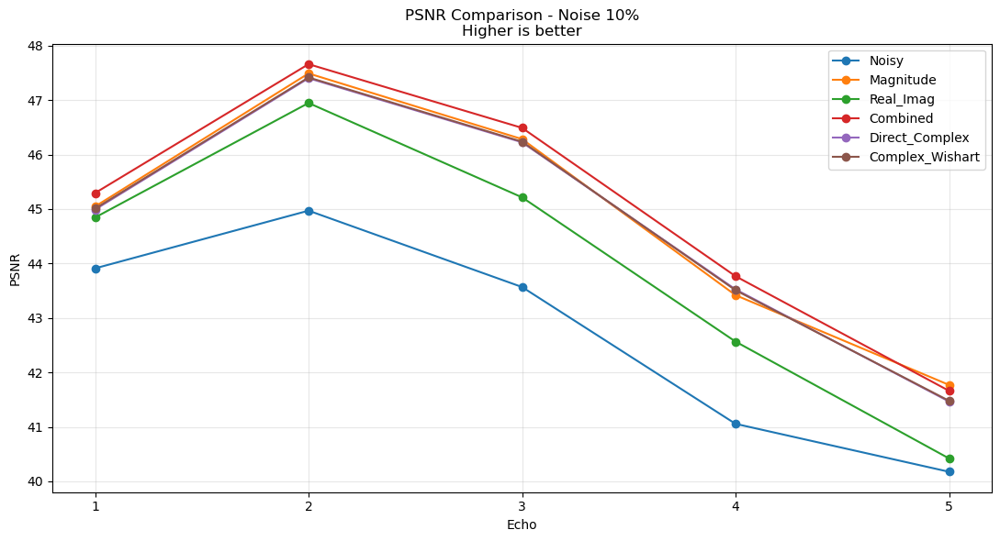

Saved: data\evaluation_final_verified\PSNR_Noise_10_Echo_Line.png


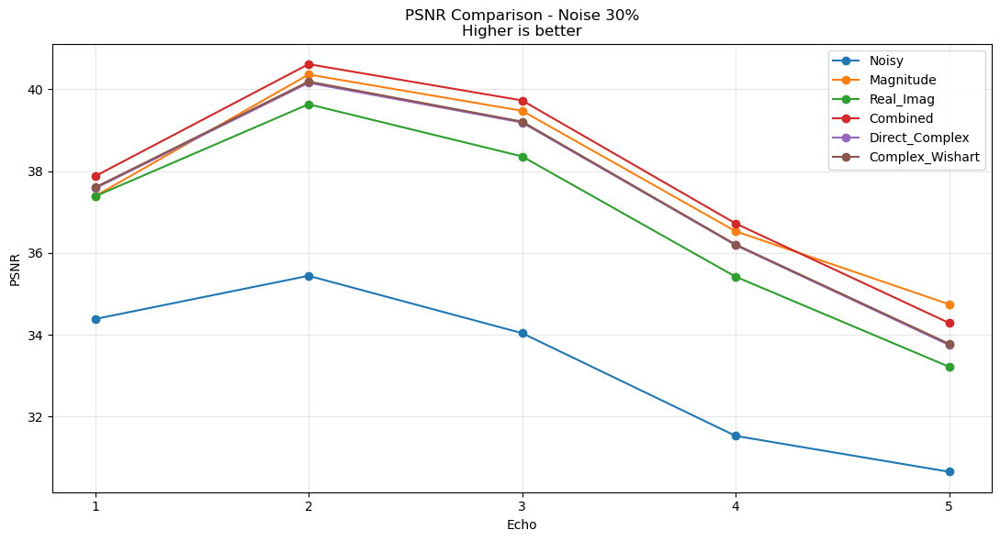

Saved: data\evaluation_final_verified\PSNR_Noise_30_Echo_Line.png


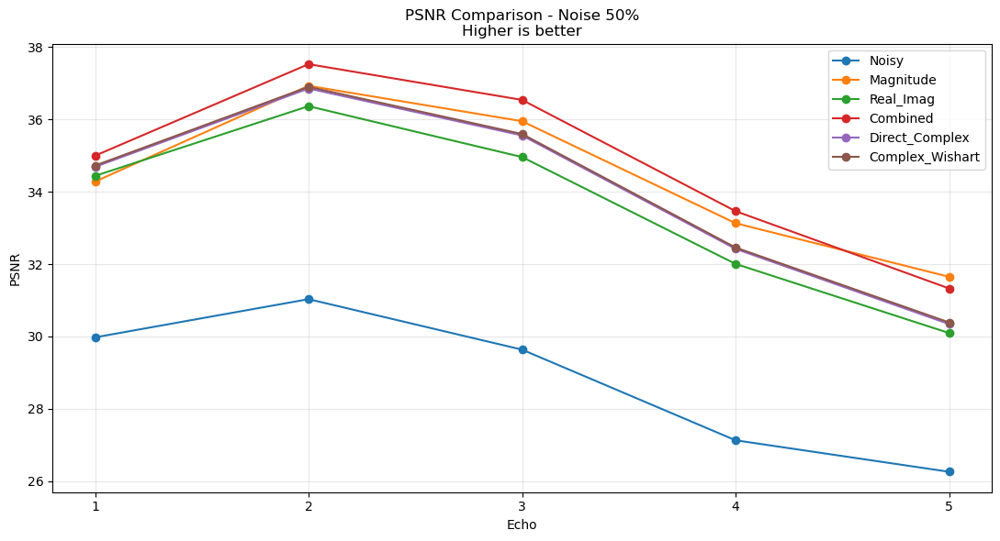

Saved: data\evaluation_final_verified\PSNR_Noise_50_Echo_Line.png

SSIM


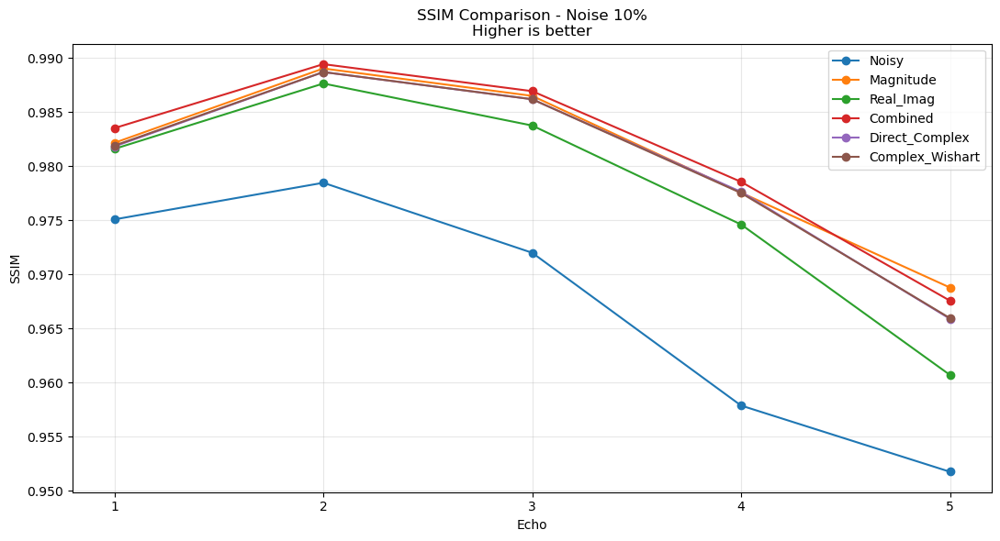

Saved: data\evaluation_final_verified\SSIM_Noise_10_Echo_Line.png


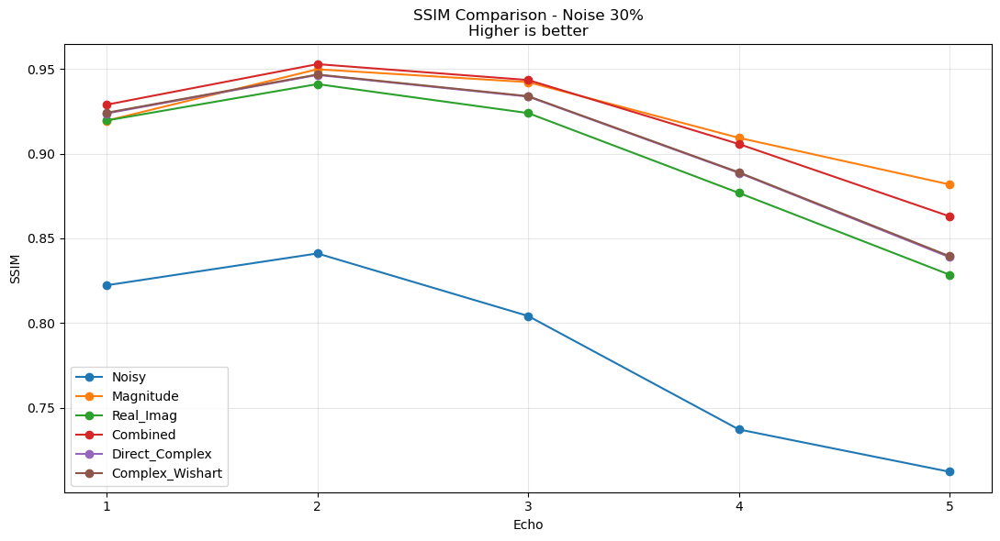

Saved: data\evaluation_final_verified\SSIM_Noise_30_Echo_Line.png


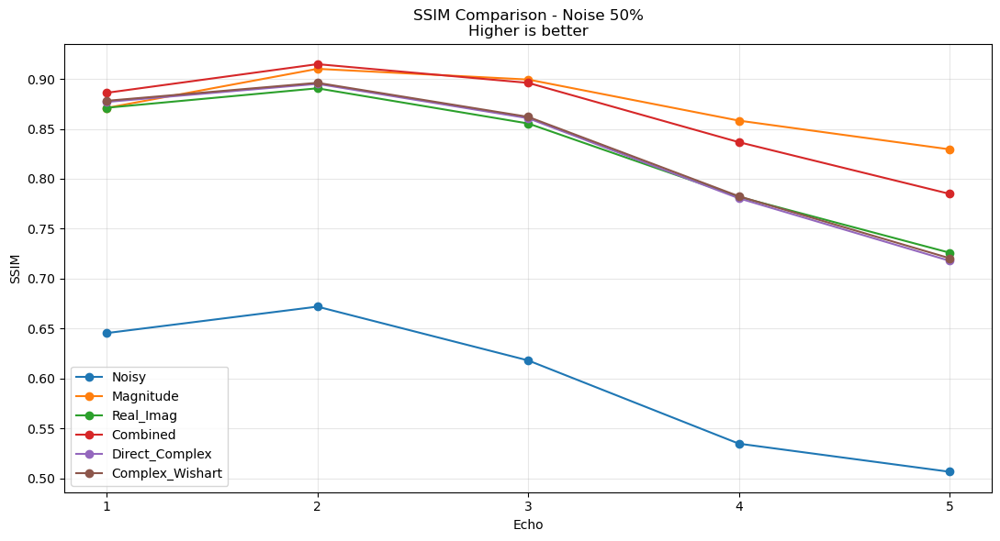

Saved: data\evaluation_final_verified\SSIM_Noise_50_Echo_Line.png

NRMSE


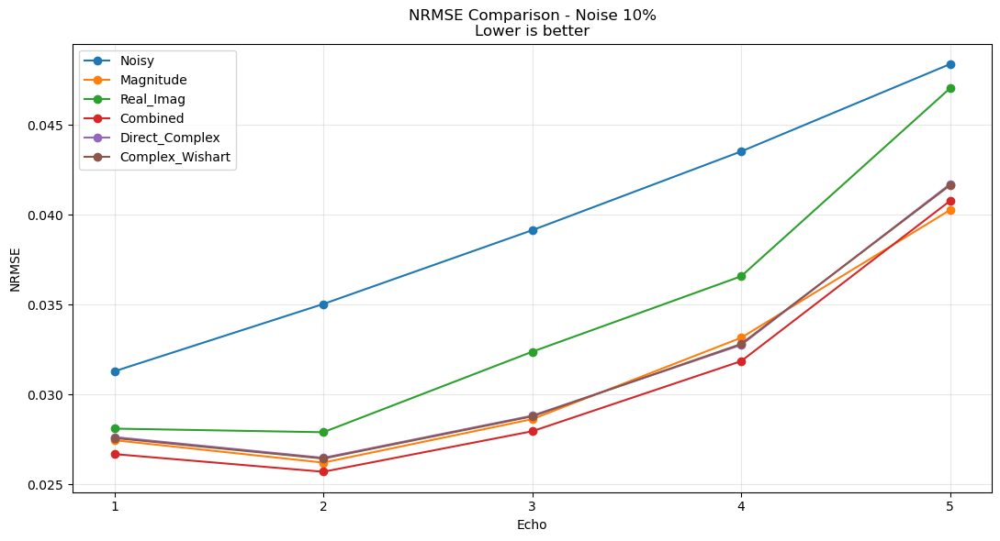

Saved: data\evaluation_final_verified\NRMSE_Noise_10_Echo_Line.png


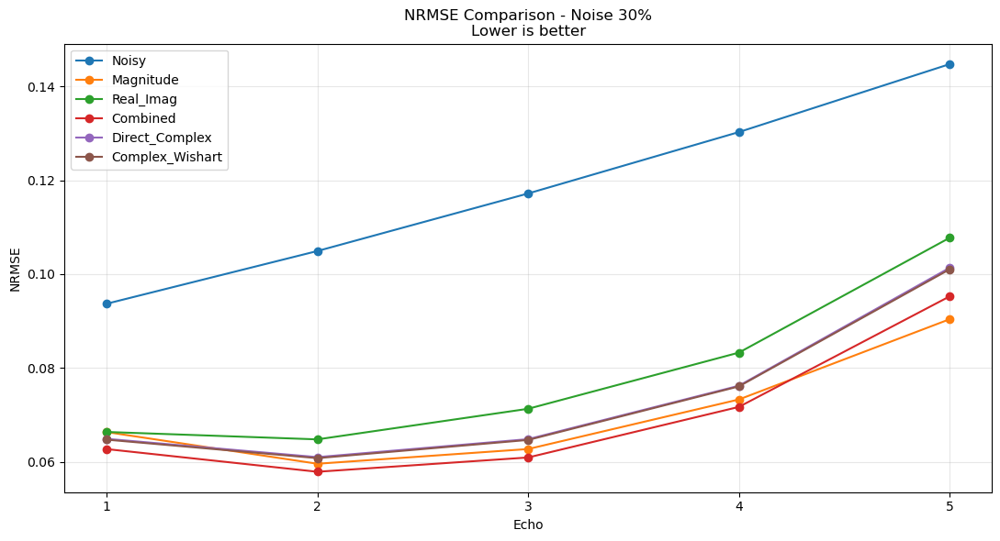

Saved: data\evaluation_final_verified\NRMSE_Noise_30_Echo_Line.png


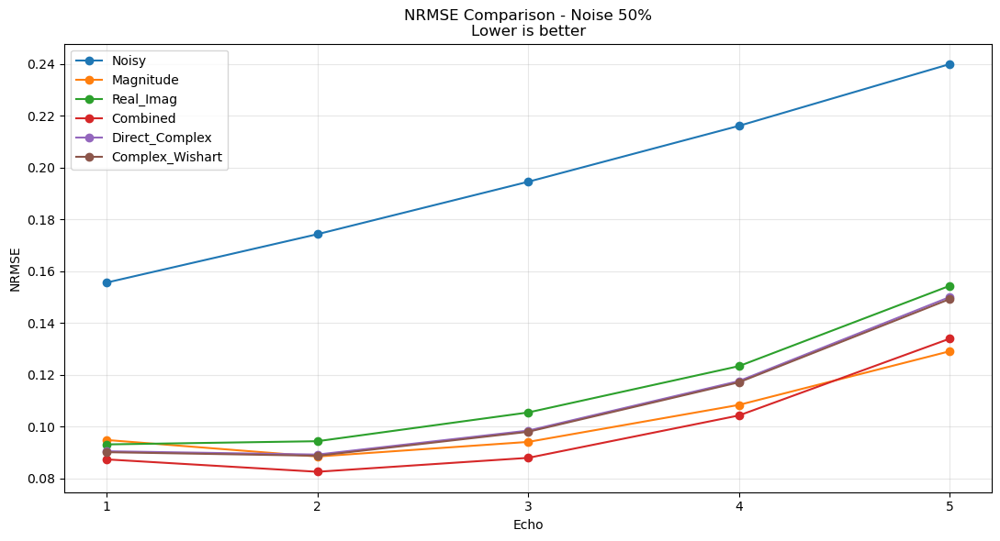

Saved: data\evaluation_final_verified\NRMSE_Noise_50_Echo_Line.png

HFEN


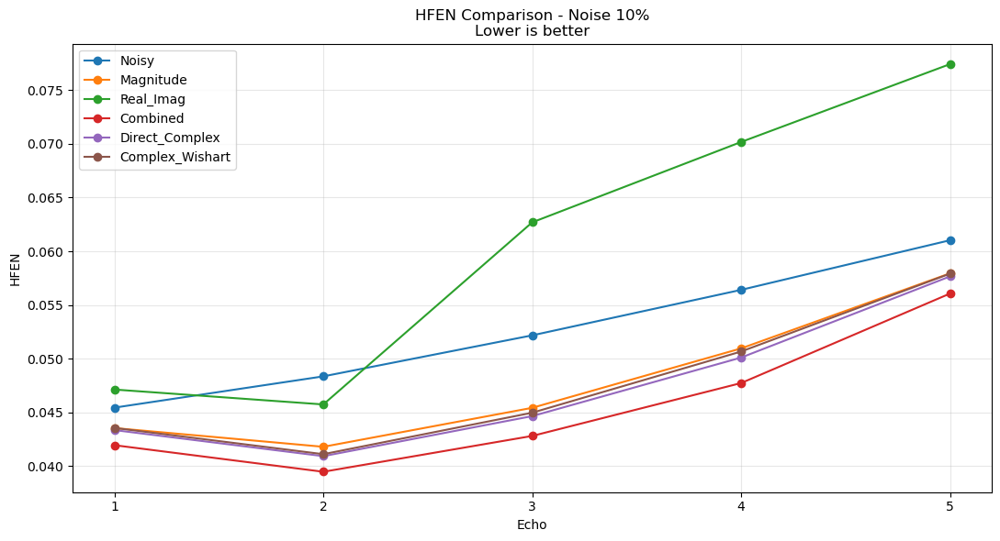

Saved: data\evaluation_final_verified\HFEN_Noise_10_Echo_Line.png


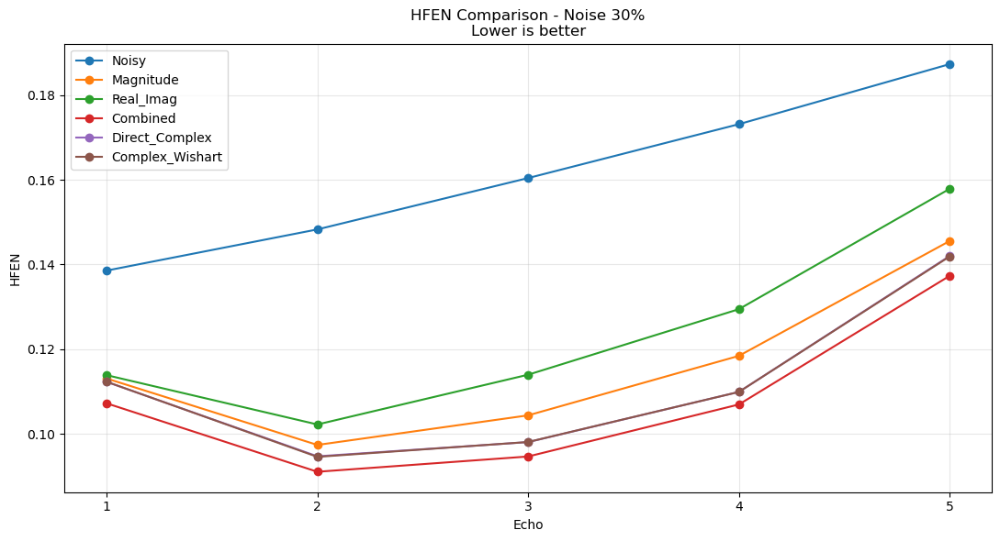

Saved: data\evaluation_final_verified\HFEN_Noise_30_Echo_Line.png


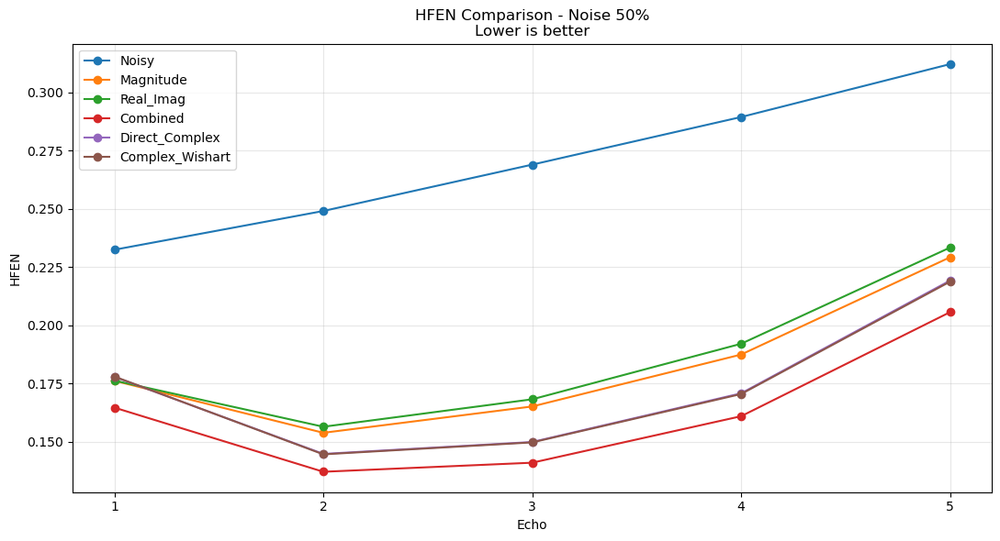

Saved: data\evaluation_final_verified\HFEN_Noise_50_Echo_Line.png


In [29]:
# ============================================================
# 9. Metric visualization
#    Reference style:
#    x-axis = Echo
#    one line = one method
#    separate figure for each noise level
# ============================================================

METRIC_INFO = {
    "PSNR": "Higher is better",
    "SSIM": "Higher is better",
    "NRMSE": "Lower is better",
    "HFEN": "Lower is better",
}

for metric, direction in METRIC_INFO.items():

    print("\n" + "=" * 80)
    print(metric)
    print("=" * 80)

    for noise_level in NOISE_LEVELS:

        temp = df_metrics[
            df_metrics["Noise"] == noise_level
        ]

        plt.figure(
            figsize=(11, 6)
        )

        for method in METHOD_ORDER:

            sub = temp[
                temp["Method"] == method
            ].sort_values("Echo")

            plt.plot(
                sub["Echo"],
                sub[metric],
                marker="o",
                label=method
            )

        plt.xlabel("Echo")
        plt.ylabel(metric)

        plt.title(
            f"{metric} Comparison - Noise {noise_level}%\n"
            f"{direction}"
        )

        plt.xticks(
            range(1, N_ECHO + 1)
        )

        plt.grid(
            alpha=0.3
        )

        plt.legend()

        plt.tight_layout()

        save_path = (
            OUT_DIR /
            f"{metric}_Noise_{noise_level}_Echo_Line.png"
        )

        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

        print("Saved:", save_path)


### 12. 영상 비교 시각화

동일한 echo와 slice에서 모든 방법을 같은 display range로 비교한다.


Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_10.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_10_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_10_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_10_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_10_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_10_r3_a0.99.mat -> denoised_complex


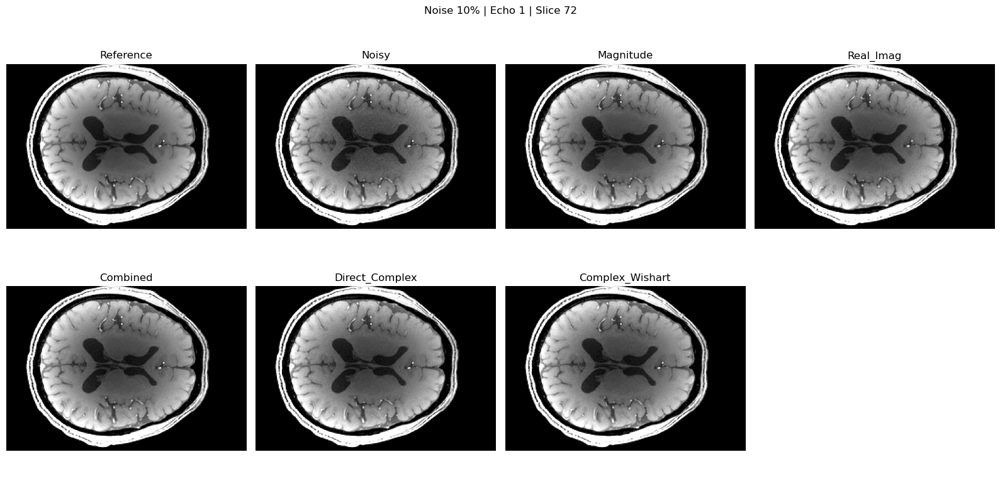

Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_30.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_30_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_30_r3_a0.99.mat -> denoised_complex


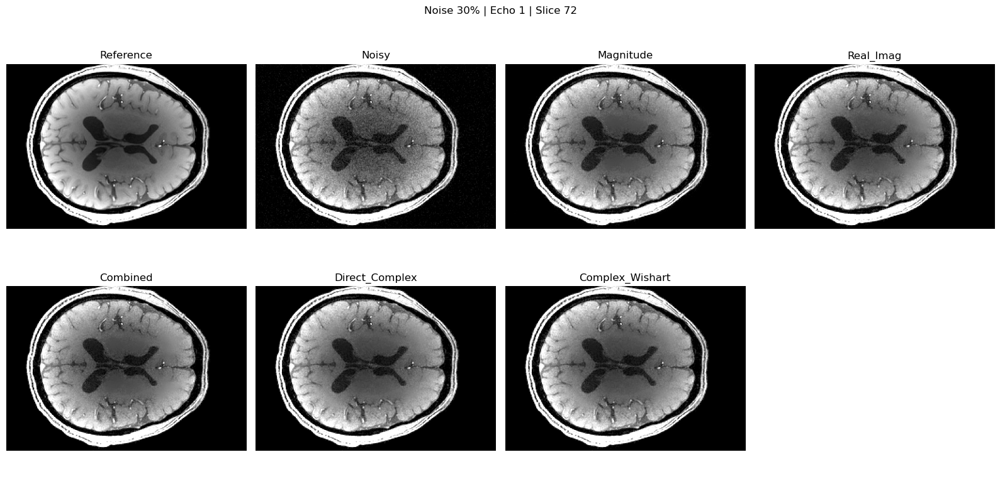

Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_50.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_50_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_50_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_50_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_50_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_50_r3_a0.99.mat -> denoised_complex


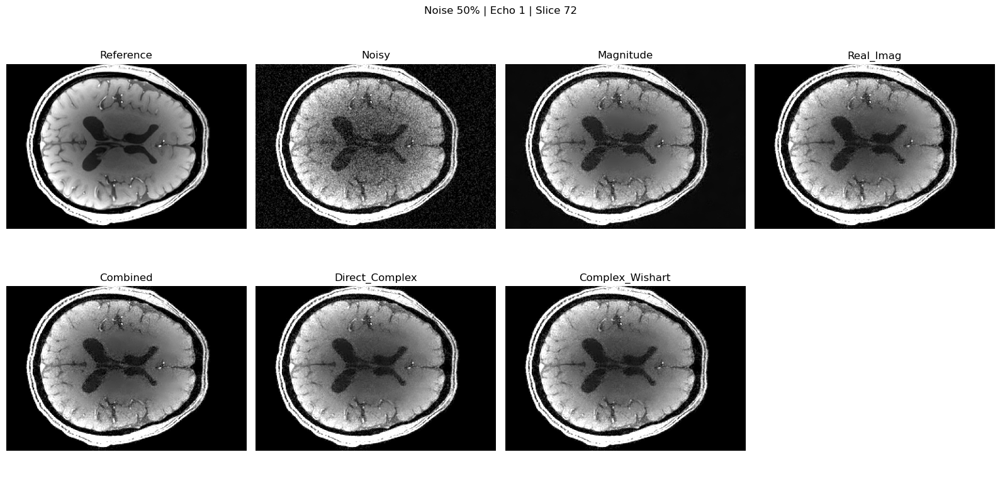

In [31]:
# ============================================================
# 10. Image comparison
# ============================================================

VIS_ECHO = 0
VIS_SLICE = orig_mag.shape[2] // 2

for noise_level in NOISE_LEVELS:

    method_images = {
        "Reference": orig_mag,
        "Noisy": load_noisy_magnitude(noise_level),
        "Magnitude": load_magnitude_result(noise_level),
        "Real_Imag": load_split_result(noise_level),
        "Combined": load_combined_result(noise_level),
        "Direct_Complex": load_direct_complex_result(noise_level),
        "Complex_Wishart": load_complex_wishart_result(noise_level),
    }

    ref_slice = orig_mag[
        :,
        :,
        VIS_SLICE,
        VIS_ECHO
    ]

    mask_slice = mask[
        :,
        :,
        VIS_SLICE
    ]

    if np.any(mask_slice):
        ref_roi = ref_slice[
            mask_slice
        ]
        vmin, vmax = np.percentile(
            ref_roi,
            [1, 99]
        )
    else:
        vmin, vmax = np.percentile(
            ref_slice,
            [1, 99]
        )

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8)
    )

    axes = axes.ravel()

    for ax, (method, volume) in zip(
        axes,
        method_images.items()
    ):

        ax.imshow(
            volume[
                :,
                :,
                VIS_SLICE,
                VIS_ECHO
            ],
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(
            method
        )

        ax.axis(
            "off"
        )

    for ax in axes[
        len(method_images):
    ]:
        ax.axis(
            "off"
        )

    fig.suptitle(
        f"Noise {noise_level}% | "
        f"Echo {VIS_ECHO + 1} | "
        f"Slice {VIS_SLICE}"
    )

    plt.tight_layout()
    plt.show()


### 13. Difference map 비교

Difference map은 `|test magnitude - reference magnitude|`를 표시한다.  
표시는 full slice이지만 **정량 metric 계산은 위에서 brain mask 내부만 사용**한다.


Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_10.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_10_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_10_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_10_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_10_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_10_r3_a0.99.mat -> denoised_complex


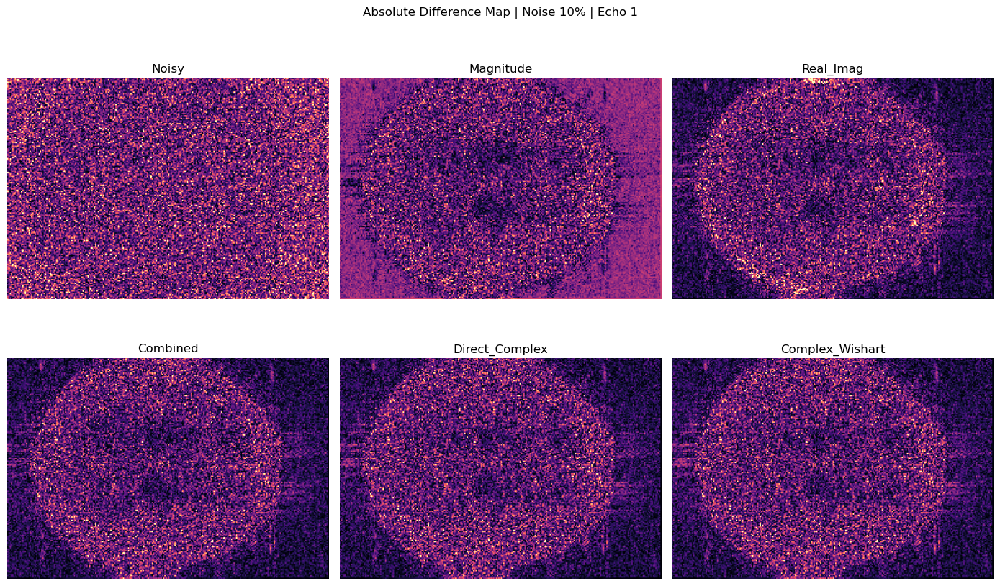

Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_30.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_30_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_30_r3_a0.99.mat -> denoised_complex


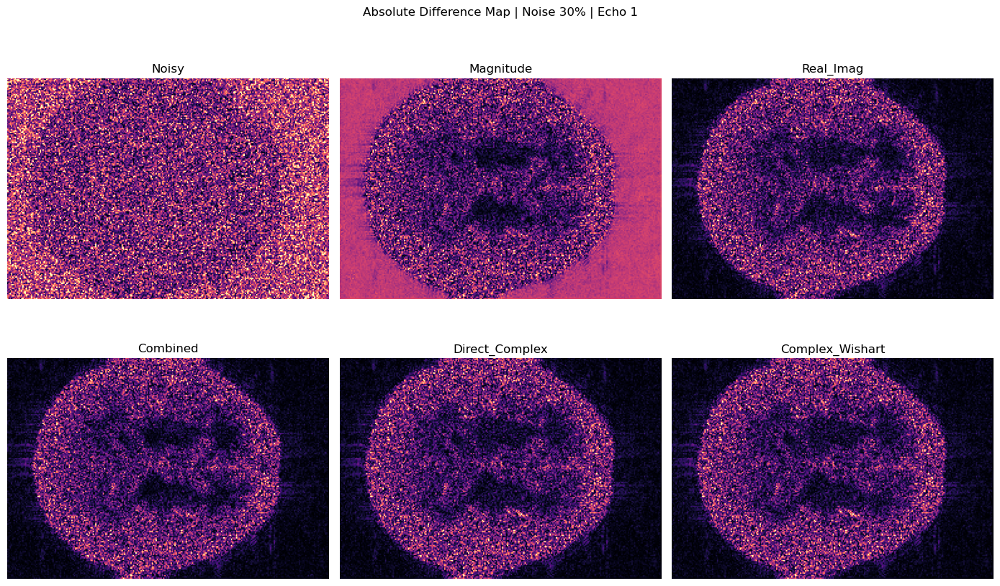

Noisy          : data\noisy_data\qsm_siemens_monopolar_noisy_50.npz -> noisy_complex
Magnitude      : data\denoised\magnitude\denoised_magnitude_50_r3.mat -> magnitude_denoised
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_50_r3.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_50_r3.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_50_r3.mat -> deno_complex
Complex Wishart: data\denoised\complex_wishart\denoised_complex_wishart_50_r3_a0.99.mat -> denoised_complex


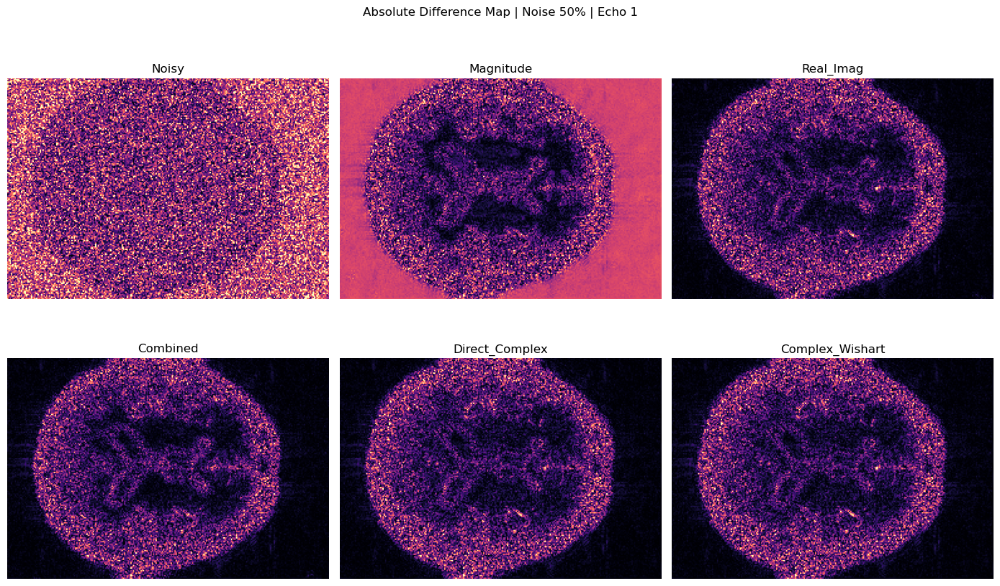

In [33]:
# ============================================================
# 11. Difference Map
# ============================================================

for noise_level in NOISE_LEVELS:

    method_images = {
        "Noisy": load_noisy_magnitude(noise_level),
        "Magnitude": load_magnitude_result(noise_level),
        "Real_Imag": load_split_result(noise_level),
        "Combined": load_combined_result(noise_level),
        "Direct_Complex": load_direct_complex_result(noise_level),
        "Complex_Wishart": load_complex_wishart_result(noise_level),
    }

    ref_slice = orig_mag[
        :,
        :,
        VIS_SLICE,
        VIS_ECHO
    ]

    diff_images = {
        method: np.abs(
            volume[
                :,
                :,
                VIS_SLICE,
                VIS_ECHO
            ]
            - ref_slice
        )
        for method, volume
        in method_images.items()
    }

    all_diff_values = np.concatenate([
        d[mask[:, :, VIS_SLICE]].ravel()
        for d in diff_images.values()
        if np.any(mask[:, :, VIS_SLICE])
    ])

    if all_diff_values.size > 0:
        vmax = np.percentile(
            all_diff_values,
            99
        )
    else:
        vmax = max(
            float(np.max(d))
            for d in diff_images.values()
        )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(14, 9)
    )

    axes = axes.ravel()

    for ax, (method, diff) in zip(
        axes,
        diff_images.items()
    ):

        im = ax.imshow(
            diff,
            cmap="magma",
            vmin=0,
            vmax=vmax
        )

        ax.set_title(
            method
        )

        ax.axis(
            "off"
        )

    fig.suptitle(
        f"Absolute Difference Map | "
        f"Noise {noise_level}% | "
        f"Echo {VIS_ECHO + 1}"
    )

    plt.tight_layout()
    plt.show()


### 14. 결과 저장

In [35]:
# ============================================================
# 12. Save CSV
# ============================================================

echo_path = (
    OUT_DIR /
    "PSNR_SSIM_NRMSE_HFEN_echo_wise_FINAL.csv"
)

mean_path = (
    OUT_DIR /
    "PSNR_SSIM_NRMSE_HFEN_mean_FINAL.csv"
)

ranking_path = (
    OUT_DIR /
    "PSNR_SSIM_NRMSE_HFEN_ranking_FINAL.csv"
)

df_metrics.to_csv(
    echo_path,
    index=False,
    encoding="utf-8-sig"
)

mean_metrics.to_csv(
    mean_path,
    index=False,
    encoding="utf-8-sig"
)

ranking_metrics.to_csv(
    ranking_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", OUT_DIR)
print()
print("Echo-wise :", echo_path.name)
print("5-echo mean:", mean_path.name)
print("Ranking   :", ranking_path.name)


저장 완료: data\evaluation_final_verified

Echo-wise : PSNR_SSIM_NRMSE_HFEN_echo_wise_FINAL.csv
5-echo mean: PSNR_SSIM_NRMSE_HFEN_mean_FINAL.csv
Ranking   : PSNR_SSIM_NRMSE_HFEN_ranking_FINAL.csv


### 15. 최종 확인

평가 방향:

- **PSNR ↑**
- **SSIM ↑**
- **NRMSE ↓**
- **HFEN ↓**

CSV 저장 위치:

```text
data/evaluation_final_verified/
```

Echo 선그래프도 같은 폴더에 저장된다.

예:

```text
PSNR_Noise_10_Echo_Line.png
PSNR_Noise_30_Echo_Line.png
PSNR_Noise_50_Echo_Line.png

SSIM_Noise_10_Echo_Line.png
...
HFEN_Noise_50_Echo_Line.png
```

각 그래프는 참고한 RSNR notebook과 동일하게:

```text
x축 = Echo
선 = Method
그래프 분리 = Noise level
```

형식으로 생성된다.


In [37]:
print("FINAL VERIFIED evaluation completed.")
print("Brain-mask voxels used for final evaluation:", int(mask.sum()))
print("Number of echoes:", N_ECHO)
print("Noise levels:", NOISE_LEVELS)
print("Methods:", METHOD_ORDER)
print("Output:", OUT_DIR.resolve())


FINAL VERIFIED evaluation completed.
Brain-mask voxels used for final evaluation: 1780588
Number of echoes: 5
Noise levels: [10, 30, 50]
Methods: ['Noisy', 'Magnitude', 'Real_Imag', 'Combined', 'Direct_Complex', 'Complex_Wishart']
Output: C:\Users\653wa\git\Graduation-Thesis\Open-QSM-MP-PCA\data\evaluation_final_verified
